# MATH7810 Python for Data Science — Individual Case Study (AY2026/27)

**Data set:** Default of Credit Card Clients (Kaggle / UCI), file `DefaultCreditCard.csv`

# 1 Exploratory data analysis

## 1.1 Introduction to the data set

The file records credit card clients in Taiwan (April to September 2005). One row is one client. The original Kaggle/UCI file has 30,000 clients; this file is a random sample of 1,000 of them (the `ID` values are not consecutive). The outcome of interest is whether the client defaulted on the next month's payment (`default.payment.next.month`, 1 = default, 0 = no default).

A card issuer earns interest and fees from customers but loses money when they default. Knowing which clients are more likely to default helps the issuer set credit limits, decide when to send reminders or tighten credit, and price risk. All amounts are in New Taiwan dollars (NT$).

| Column | Meaning |
|---|---|
| `ID` | Client identifier. Not a measurement. |
| `LIMIT_BAL` | Amount of given credit (NT$), including individual and family/supplementary credit. |
| `SEX` | 1 = male, 2 = female. |
| `EDUCATION` | 1 = graduate school, 2 = university, 3 = high school, 4 = others, 5 = unknown, 6 = unknown. |
| `MARRIAGE` | 1 = married, 2 = single, 3 = others. |
| `AGE` | Age in years. |
| `PAY_0`, `PAY_2` … `PAY_6` | Repayment status in September (`PAY_0`), August (`PAY_2`) … April (`PAY_6`). −1 = pay duly, 1 = payment delayed one month, 2 = delayed two months … 9 = delayed nine months or more (official Kaggle description). |
| `BILL_AMT1` … `BILL_AMT6` | Amount of bill statement (NT$) in September … April. |
| `PAY_AMT1` … `PAY_AMT6` | Amount of previous payment (NT$) in September … April. |
| `default.payment.next.month` | Default next month (1 = yes, 0 = no). Binary outcome. |

In [1]:
import pandas as pd
import numpy as np

# One row is one client.
df = pd.read_csv("DefaultCreditCard.csv")
df = df.rename(columns={"default.payment.next.month": "default"})

print("rows, columns:", df.shape)
print("ID unique:", df["ID"].is_unique, "| duplicated rows:", int(df.duplicated().sum()))
print("total missing values:", int(df.isna().sum().sum()))
print()
print(df.dtypes.to_string())

rows, columns: (1000, 25)
ID unique: True | duplicated rows: 0
total missing values: 0

ID             int64
LIMIT_BAL    float64
SEX            int64
EDUCATION      int64
MARRIAGE       int64
AGE            int64
PAY_0          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5          int64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
default        int64


### Data checks and cleaning

There are no missing values and no duplicated rows. All variables are stored as numbers, but `SEX`, `EDUCATION`, `MARRIAGE` and `default` are categorical codes and the `PAY_*` columns are ordinal codes (not amounts), so they should not be averaged like measurements. Next I check the codes against the data documentation.

In [2]:
# Check the categorical codes against the documentation.
for column in ["SEX", "EDUCATION", "MARRIAGE", "default"]:
    print(column, df[column].value_counts().sort_index().to_dict())

# Negative bill amounts (a credit balance, for example after an overpayment).
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
print("\nclients with a negative bill in each month:")
print((df[bill_cols] < 0).sum().to_string())

# Repayment status codes. The description only defines -1 and 1 to 9.
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
print("\nPAY_0 codes:", df["PAY_0"].value_counts().sort_index().to_dict())
print("rows with any undocumented code (-2 or 0) in PAY_0 to PAY_6:", int(df[pay_cols].isin([-2, 0]).any(axis=1).sum()))

SEX {1: 397, 2: 603}
EDUCATION {1: 343, 2: 479, 3: 162, 4: 5, 5: 10, 6: 1}
MARRIAGE {0: 1, 1: 465, 2: 526, 3: 8}
default {0: 784, 1: 216}

clients with a negative bill in each month:
BILL_AMT1    20
BILL_AMT2    20
BILL_AMT3    16
BILL_AMT4    25
BILL_AMT5    27
BILL_AMT6    21

PAY_0 codes: {-2: 112, -1: 201, 0: 451, 1: 138, 2: 79, 3: 10, 4: 4, 6: 2, 7: 1, 8: 2}
rows with any undocumented code (-2 or 0) in PAY_0 to PAY_6: 857


`EDUCATION` has the undocumented codes 5 and 6 (and the documented 4 = "others"). They are very few (16 rows in total), so I merge 4, 5 and 6 into one category "Others/unknown".   
`MARRIAGE` has one row coded 0, which is not in the documentation. I merge it into 3 = "Others".  
The repayment status columns contain the codes −2 and 0, which the official description does not define (it defines −1 = pay duly and 1 to 9 = months of delay). They are very common (about 56% of September values), so I do not delete them. Both are *smaller than 1*, so they are certainly not a payment delay. I therefore treat every `PAY_0 <= 0` as "not late" and only `PAY_0 >= 1` as late; this does not depend on what −2 and 0 exactly mean. (Discussions of this data set commonly read −2 as "no consumption" and 0 as "revolving credit, minimum payment made", but that is an unofficial reading and is not used in any test below.)  
Negative `BILL_AMT` values are kept: they are credit balances and not data errors, but I will remember that they exist when I compute statistics and correlations of bill amounts.  
I add readable label columns and a flag `late_sep` (1 if `PAY_0 >= 1`, i.e. the client was at least one month late in September).

In [3]:
df["sex_label"] = df["SEX"].map({1: "Male", 2: "Female"})
df["edu_label"] = df["EDUCATION"].map({1: "Graduate school", 2: "University", 3: "High school"}).fillna("Others/unknown")
df["marriage_label"] = df["MARRIAGE"].map({1: "Married", 2: "Single"}).fillna("Others")
df["late_sep"] = (df["PAY_0"] >= 1).astype(int)

# Repayment status in September grouped for the later plots.
def pay_group(x):
    if x <= -1:
        return "Code -2 or -1\n(not late)"
    if x == 0:
        return "Code 0\n(not late)"
    if x == 1:
        return "1 month\nlate"
    if x == 2:
        return "2 months\nlate"
    return "3+ months\nlate"
df["pay_group"] = df["PAY_0"].apply(pay_group)

print(df["edu_label"].value_counts().to_string())
print()
print(df["marriage_label"].value_counts().to_string())
print()
print("late in September (PAY_0 >= 1):", int(df["late_sep"].sum()), "clients")

edu_label
University         479
Graduate school    343
High school        162
Others/unknown      16

marriage_label
Single     526
Married    465
Others       9

late in September (PAY_0 >= 1): 236 clients


### Categorical variables


In [4]:
# Count and percentage for each category.
for column in ["sex_label", "edu_label", "marriage_label", "default"]:
    counts = df[column].value_counts()
    table = pd.DataFrame({"count": counts, "percentage": (100 * counts / len(df)).round(1)})
    print(column)
    print(table.to_string())
    print()

sex_label
           count  percentage
sex_label                   
Female       603        60.3
Male         397        39.7

edu_label
                 count  percentage
edu_label                         
University         479        47.9
Graduate school    343        34.3
High school        162        16.2
Others/unknown      16         1.6

marriage_label
                count  percentage
marriage_label                   
Single            526        52.6
Married           465        46.5
Others              9         0.9

default
         count  percentage
default                   
0          784        78.4
1          216        21.6



## 1.2 Numerical descriptive statistics

The five-number summary is shown together with the sample mean and standard deviation. The same quartiles are then used to flag outliers with the rule Q1 − 1.5 × IQR and Q3 + 1.5 × IQR.


In [5]:
numeric = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]
summary = df[numeric].quantile([0, 0.25, 0.5, 0.75, 1]).T
summary.columns = ["Minimum", "Q1", "Median", "Q3", "Maximum"]
summary.insert(0, "Std dev", df[numeric].std().values)
summary.insert(0, "Mean", df[numeric].mean().values)
print(summary.round(1).to_string())

# Outliers by the 1.5 x IQR rule.
rows = []
for column in numeric:
    values = df[column]
    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((values < lower) | (values > upper)).sum())
    rows.append([column, round(lower, 1), round(upper, 1), n_out, round(100 * n_out / len(values), 1)])
print()
print(pd.DataFrame(rows, columns=["variable", "lower fence", "upper fence", "outliers", "percentage"]).to_string(index=False))

               Mean   Std dev  Minimum       Q1    Median        Q3   Maximum
LIMIT_BAL  174080.0  132714.6  10000.0  60000.0  150000.0  250000.0  680000.0
AGE            35.4       9.4     21.0     28.0      34.0      41.0      66.0
BILL_AMT1   51341.7   74935.4  -9095.0   2902.5   20952.5   68287.8  568532.0
PAY_AMT1     5942.8   15732.9      0.0    861.8    2100.0    5253.0  244500.0

 variable  lower fence  upper fence  outliers  percentage
LIMIT_BAL    -225000.0     535000.0         5         0.5
      AGE          8.5         60.5        13         1.3
BILL_AMT1     -95175.4     166365.6        76         7.6
 PAY_AMT1      -5725.1      11839.9        87         8.7


The mean of `LIMIT_BAL` (about NT$174,000) is above its median (NT$150,000), and the means of `BILL_AMT1` and `PAY_AMT1` are far above their medians, so these three variables are right-skewed. `PAY_AMT1` has the largest relative spread: its standard deviation is about 2.6 times its mean, and a few clients pay more than NT$200,000 in one month. For these skewed variables the median describes a "typical" client better than the mean. The outliers are real, large customers rather than recording errors, so I do not delete them; I check later that the main conclusions do not depend on them. `AGE` is roughly symmetric, with a typical client in the mid-30s.

### Default rate overall and by group

In [6]:
from scipy import stats

n = len(df)
p_hat = df["default"].mean()
se = np.sqrt(p_hat * (1 - p_hat) / n)
z = stats.norm.ppf(0.975)
print(f"overall default rate: {p_hat:.3f}  (n = {n})")
print(f"95% z interval: ({p_hat - z*se:.3f}, {p_hat + z*se:.3f})")
print()
for column in ["sex_label", "edu_label", "marriage_label", "pay_group"]:
    table = df.groupby(column)["default"].agg(["count", "sum", "mean"])
    table.columns = ["clients", "defaults", "default rate"]
    print(table.rename(index=lambda s: str(s).replace("\n", " ")).round(3).to_string())
    print()

overall default rate: 0.216  (n = 1000)
95% z interval: (0.190, 0.242)

           clients  defaults  default rate
sex_label                                 
Female         603       124         0.206
Male           397        92         0.232

                 clients  defaults  default rate
edu_label                                       
Graduate school      343        55         0.160
High school          162        47         0.290
Others/unknown        16         1         0.062
University           479       113         0.236

                clients  defaults  default rate
marriage_label                                 
Married             465       107         0.230
Others                9         3         0.333
Single              526       106         0.202

                          clients  defaults  default rate
pay_group                                                
1 month late                  138        46         0.333
2 months late                  79        53  

### Correlation between numerical variables

The sample correlation $r=\dfrac{\sum (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum (x_i-\bar x)^2\sum (y_i-\bar y)^2}}$ measures the strength of a linear association. Spearman's rank correlation is added as a check because the variables are skewed.

In [7]:
print("Pearson correlation")
print(df[numeric].corr().round(3).to_string())
print()
print("Spearman rank correlation")
print(df[numeric].corr(method="spearman").round(3).to_string())

Pearson correlation
           LIMIT_BAL    AGE  BILL_AMT1  PAY_AMT1
LIMIT_BAL      1.000  0.187      0.255     0.233
AGE            0.187  1.000      0.019     0.043
BILL_AMT1      0.255  0.019      1.000     0.127
PAY_AMT1       0.233  0.043      0.127     1.000

Spearman rank correlation
           LIMIT_BAL    AGE  BILL_AMT1  PAY_AMT1
LIMIT_BAL      1.000  0.218     -0.022     0.233
AGE            0.218  1.000     -0.076    -0.041
BILL_AMT1     -0.022 -0.076      1.000     0.441
PAY_AMT1       0.233 -0.041      0.441     1.000


All correlations among these four variables are weak to moderate. The strongest are `LIMIT_BAL` with `BILL_AMT1` (Pearson r ≈ 0.26) and with `PAY_AMT1` (r ≈ 0.23): clients with higher limits tend to have larger bills and make larger payments, which is plausible because they can spend more. Note that the Pearson and Spearman values for `LIMIT_BAL` and `BILL_AMT1` disagree strongly (Spearman is close to 0), which shows that the Pearson correlation is driven by a small number of very large bills and not by a general pattern. `AGE` is hardly related to bills or payments.

## 1.3 Exploratory analysis with visualizations

### 1.3.1 Default rate by September repayment status

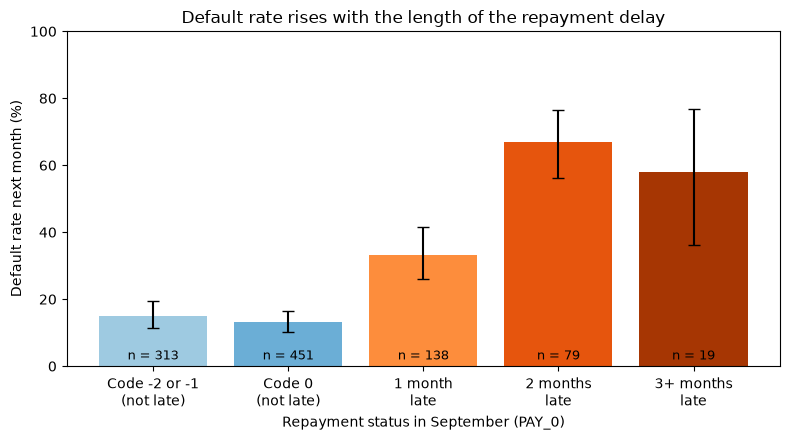

pay_group
Code -2 or -1 (not late)    15.0
Code 0 (not late)           13.1
1 month late                33.3
2 months late               67.1
3+ months late              57.9


In [8]:
import matplotlib.pyplot as plt

def wilson(k, n, conf=0.95):
    # Wilson score interval for a proportion (more reliable than the normal interval for small groups).
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

order = ["Code -2 or -1\n(not late)", "Code 0\n(not late)", "1 month\nlate", "2 months\nlate", "3+ months\nlate"]
g = df.groupby("pay_group")["default"].agg(["sum", "count"]).reindex(order)
rate = g["sum"] / g["count"]
ci = np.array([wilson(k, m) for k, m in zip(g["sum"], g["count"])])
err = np.vstack([rate - ci[:, 0], ci[:, 1] - rate])

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(order, 100 * rate, yerr=100 * err, capsize=4, color=["#9ecae1", "#6baed6", "#fd8d3c", "#e6550d", "#a63603"])
for bar, m in zip(bars, g["count"]):
    ax.text(bar.get_x() + bar.get_width() / 2, 2, f"n = {m}", ha="center", fontsize=9, color="black")
ax.set_ylabel("Default rate next month (%)")
ax.set_xlabel("Repayment status in September (PAY_0)")
ax.set_title("Default rate rises with the length of the repayment delay")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()
print((100 * rate).rename(index=lambda s: s.replace("\n", " ")).round(1).to_string())

### Interpretation:     
The default rate is about 15% for clients with code −2 or −1 and about 13% for clients with code 0; neither group is late, and their rates are similar. It rises to 33% for clients one month late and to 67% for clients two months late. The 3+ months bar (58%) rests on only 19 clients and its wide interval overlaps the 2-month bar, so we cannot conclude that it is lower. Repayment delay is clearly associated with default, and this motivates Research Question 2.

### Business implication:     
    
The most recent repayment status is a cheap and powerful early-warning signal. The bank can put clients who are already one month late into a reminder or collection programme *before* the next due date, and can review credit limits for clients with two or more months of delay.

### 1.3.2 Credit limit and default

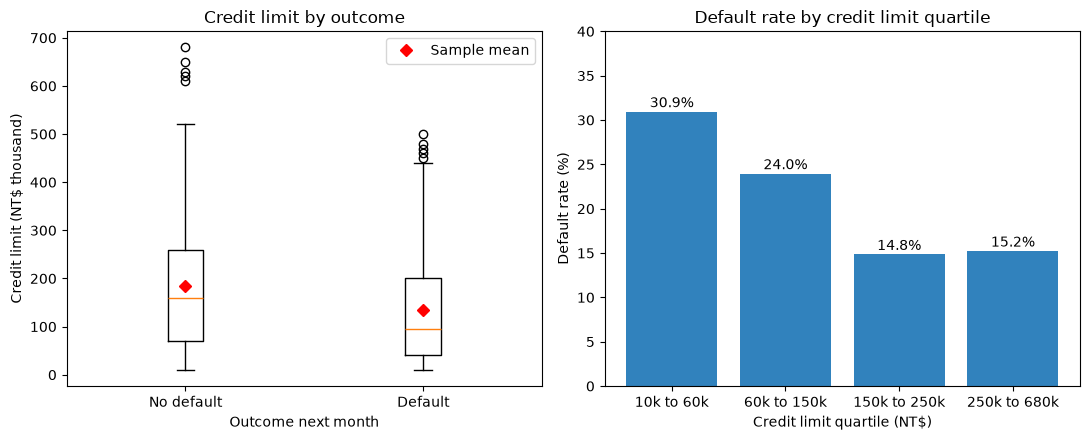

             mean    median
default                    
0        185217.0  160000.0
1        133657.0   95000.0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Left: boxplot of the credit limit for each outcome, with the sample mean as a diamond.
labels = ["No default", "Default"]
groups = [df.loc[df["default"] == k, "LIMIT_BAL"] / 1000 for k in [0, 1]]
axes[0].boxplot(groups)
axes[0].plot([1, 2], [g.mean() for g in groups], "D", color="red", label="Sample mean")
axes[0].set_xticks([1, 2])
axes[0].set_xticklabels(labels)
axes[0].set_ylabel("Credit limit (NT$ thousand)")
axes[0].set_xlabel("Outcome next month")
axes[0].set_title("Credit limit by outcome")
axes[0].legend()

# Right: default rate by credit limit quartile.
quartile = pd.qcut(df["LIMIT_BAL"], 4)
rates = df.groupby(quartile, observed=True)["default"].agg(["mean", "count"])
names = [f"{int(i.left/1000) if i.left > 10000 else 10}k to {int(i.right/1000)}k" for i in rates.index]
axes[1].bar(names, 100 * rates["mean"], color="#3182bd")
for x, (m, c) in enumerate(zip(rates["mean"], rates["count"])):
    axes[1].text(x, 100 * m + 0.5, f"{100*m:.1f}%", ha="center")
axes[1].set_xlabel("Credit limit quartile (NT$)")
axes[1].set_ylabel("Default rate (%)")
axes[1].set_ylim(0, 40)
axes[1].set_title("Default rate by credit limit quartile")
plt.tight_layout()
plt.show()
print(df.groupby("default")["LIMIT_BAL"].agg(["mean", "median"]).round(0).to_string())

### Interpretation:     
Defaulters have a lower credit limit: the median is NT$95,000 against NT$160,000 for non-defaulters, and the mean is about NT$134,000 against NT$185,000. The right panel shows the same pattern: 30.9% of clients in the lowest limit quartile defaulted, 24.0% in the second quartile, and about 15% in each of the two top quartiles. The risk falls as the limit rises and then levels off.

### Business implication:
Clients with small limits are the riskiest group, so a low limit is not a safe way of controlling losses by itself; the bank may want to look at how limits are granted and monitored at the low end. 

### 1.3.3 Credit limit and September bill

Pearson r = 0.255, Spearman = -0.022


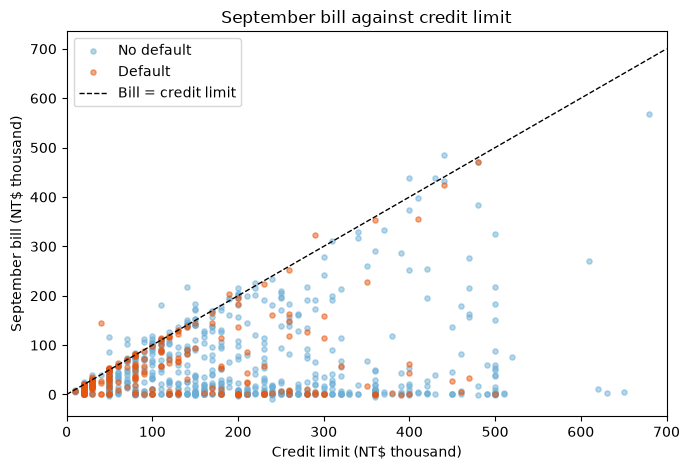

clients whose September bill exceeds the credit limit: 86


In [10]:
r_pearson = df["LIMIT_BAL"].corr(df["BILL_AMT1"])
r_spearman = df["LIMIT_BAL"].corr(df["BILL_AMT1"], method="spearman")
print(f"Pearson r = {r_pearson:.3f}, Spearman = {r_spearman:.3f}")

fig, ax = plt.subplots(figsize=(7, 4.8))
for k, color, name in [(0, "#6baed6", "No default"), (1, "#e6550d", "Default")]:
    sub = df[df["default"] == k]
    ax.scatter(sub["LIMIT_BAL"] / 1000, sub["BILL_AMT1"] / 1000, s=14, alpha=0.5, color=color, label=name)
ax.plot([0, 700], [0, 700], "k--", lw=1, label="Bill = credit limit")
ax.set_xlim(0, 700)
ax.set_xlabel("Credit limit (NT$ thousand)")
ax.set_ylabel("September bill (NT$ thousand)")
ax.set_title("September bill against credit limit")
ax.legend()
plt.tight_layout()
plt.show()

over = int((df["BILL_AMT1"] > df["LIMIT_BAL"]).sum())
print("clients whose September bill exceeds the credit limit:", over)

### Interpretation: 
Most clients have a September bill far below their limit, and many are near zero (they pay in full or barely use the card). A visible group lies on or just below the dashed line, that is, they use their whole limit; this is especially common at limits below NT$150,000, and 86 clients (8.6%) have a bill above their limit. Orange points (defaults) appear along the dashed line at low limits more often than among the low-bill clients. The overall pattern is not a clean straight line, which is consistent with the gap between Pearson r (0.26) and Spearman (−0.02) found in Section 1.2.

### Business implication:
Utilisation (bill divided by limit) is a more informative risk feature than the raw bill amount. Clients close to or above the dashed line are using all of their credit and deserve monitoring.

### 1.3.4 Default rate by education and sex

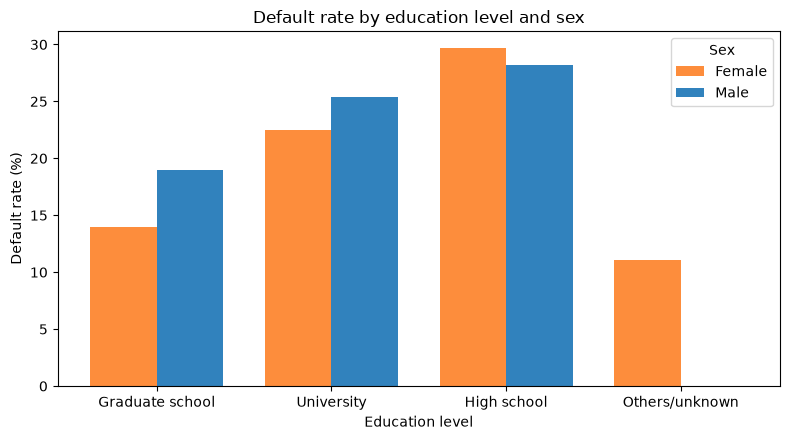

sex_label        Female  Male
edu_label                    
Graduate school    13.9  19.0
University         22.5  25.4
High school        29.7  28.2
Others/unknown     11.1   0.0

sex_label        Female  Male
edu_label                    
Graduate school     201   142
University          302   177
High school          91    71
Others/unknown        9     7


In [11]:
edu_order = ["Graduate school", "University", "High school", "Others/unknown"]
table = df.pivot_table(index="edu_label", columns="sex_label", values="default", aggfunc="mean").reindex(edu_order) * 100
counts = df.pivot_table(index="edu_label", columns="sex_label", values="default", aggfunc="count").reindex(edu_order)

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(edu_order))
w = 0.38
ax.bar(x - w / 2, table["Female"], w, label="Female", color="#fd8d3c")
ax.bar(x + w / 2, table["Male"], w, label="Male", color="#3182bd")
ax.set_xticks(x)
ax.set_xticklabels(edu_order)
ax.set_xlabel("Education level")
ax.set_ylabel("Default rate (%)")
ax.set_title("Default rate by education level and sex")
ax.legend(title="Sex")
plt.tight_layout()
plt.show()
print(table.round(1).to_string())
print()
print(counts.to_string())

### Interpretation: 
Default falls as education rises: 16.0% for graduate school, 23.6% for university and 29.0% for high school overall. Within each of these three levels the sexes are close; men are a little higher at graduate and university level and women a little higher/equal at high school, so there is no consistent gender pattern. The "Others/unknown" bars rest on 9 women and 7 men and carry almost no information.

### Business implication:
Education may be associated with risk, but the groups are small after splitting by sex, so differences should not be over-interpreted. Also, using sex directly in credit decisions is ethically and legally problematic in many jurisdictions; behavioural variables (repayment history, utilisation) are better and fairer bases for decisions.

# 2 Research questions and statistical analysis

## 2.1 Three research questions proposed without AI

Is the mean credit limit different for clients who default and clients who do not?

The credit limit is the one risk lever the bank directly controls. If defaulters have a different average limit, the limit-setting policy is related to risk. It can be answered with a two-sample test for means because `LIMIT_BAL` is numerical and `default` splits the sample into two independent groups.

Is the proportion of defaults higher among clients who were late in September than among clients who were not late?  

If late clients default far more often, a late payment is a practical early-warning trigger for collection actions. Both variables are binary, so a two-proportion z-test and interval fit.

Is the default proportion the same for male and female clients?
  
It checks whether a gender gap exists in this portfolio (for fairness monitoring and portfolio understanding). It is also a two-proportion problem.

## 2.2 Three research questions proposed by Copilot


Prompt:   
I have a random sample of 1,000 credit card clients with credit limit, sex, education, marriage, age, six months of repayment status, bill and payment amounts, and a binary default indicator. Propose three business-relevant research questions that I can answer with confidence intervals, hypothesis tests, correlation or simple linear regression.

Question:  
What proportion of clients defaulted on the next month’s payment?  
Is default more common among clients with recent repayment delays?  
Are higher credit limits associated with higher billed balances?

## 2.3 Final Three Questions


Q1: Is the mean credit limit different for clients who default and clients who do not?  
Mainly me.   

Q2: Is default more common among clients with recent repayment delays?   
Both. AI try a wider definition of delay.

Q3: Is the default proportion the same for male and female clients?  
Mainly me.

### Research question 1: Mean credit limit of defaulters and non-defaulters

Let $\mu_1$ be the mean credit limit of clients who default and $\mu_0$ that of clients who do not.

$H_0:\ \mu_1=\mu_0 \qquad H_1:\ \mu_1\neq\mu_0 \qquad (\alpha=0.05)$

Welch's two-sample t-test (independent groups, population standard deviations unknown and possibly unequal):

$$t=\frac{\bar x_1-\bar x_0}{\sqrt{\dfrac{s_1^2}{n_1}+\dfrac{s_0^2}{n_0}}},\qquad df\approx\frac{\left(\frac{s_1^2}{n_1}+\frac{s_0^2}{n_0}\right)^2}{\frac{(s_1^2/n_1)^2}{n_1-1}+\frac{(s_0^2/n_0)^2}{n_0-1}}$$

The two groups are different clients (independent), the outcome is numerical, and the sample standard deviations differ (about 116k vs 135k), so Welch's version, which does not assume equal variances, is safer than the pooled t-test. `LIMIT_BAL` is right-skewed, but both groups are large (216 and 784), so by the central limit theorem the sample means are approximately normal. As a robustness check I also run the Mann–Whitney test, which does not rely on normality.

In [12]:
d1 = df.loc[df["default"] == 1, "LIMIT_BAL"]
d0 = df.loc[df["default"] == 0, "LIMIT_BAL"]
n1, n0 = len(d1), len(d0)
m1, m0 = d1.mean(), d0.mean()
v1, v0 = d1.var(ddof=1) / n1, d0.var(ddof=1) / n0

t_stat = (m1 - m0) / np.sqrt(v1 + v0)
dof = (v1 + v0) ** 2 / (v1**2 / (n1 - 1) + v0**2 / (n0 - 1))
p_value = 2 * stats.t.sf(abs(t_stat), dof)
half = stats.t.ppf(0.975, dof) * np.sqrt(v1 + v0)

print(f"default:     n = {n1}, mean = {m1:,.0f}, sd = {d1.std():,.0f}")
print(f"no default:  n = {n0}, mean = {m0:,.0f}, sd = {d0.std():,.0f}")
print(f"difference in means = {m1 - m0:,.0f}")
print(f"Welch t = {t_stat:.3f}, df = {dof:.1f}, p-value = {p_value:.2e}")
print(f"95% CI for mu1 - mu0: ({m1 - m0 - half:,.0f}, {m1 - m0 + half:,.0f})")

# Check against scipy, and a rank-based robustness check.
check = stats.ttest_ind(d1, d0, equal_var=False)
print(f"scipy Welch: t = {check.statistic:.3f}, p = {check.pvalue:.2e}")
mw = stats.mannwhitneyu(d1, d0, alternative="two-sided")
print(f"Mann-Whitney U p-value = {mw.pvalue:.2e}")

default:     n = 216, mean = 133,657, sd = 115,995
no default:  n = 784, mean = 185,217, sd = 134,917
difference in means = -51,559
Welch t = -5.576, df = 390.3, p-value = 4.61e-08
95% CI for mu1 - mu0: (-69,740, -33,379)
scipy Welch: t = -5.576, p = 4.61e-08
Mann-Whitney U p-value = 4.01e-08


Clients who default have a mean credit limit about 51,600 lower than clients who do not. Welch's test gives t ≈ −5.58 with about 390 degrees of freedom and a p-value of about 5 × 10⁻⁸, far below 0.05, so we reject H₀. The 95% confidence interval for μ₁ − μ₀ is roughly; it excludes 0. The Mann–Whitney test agrees (p ≈ 4 × 10⁻⁸), so the conclusion does not depend on the skewness or the outliers.

In this sample, defaulting clients had clearly lower credit limits than clients who paid. Based on this we can say that low-limit clients are a higher-risk segment, and the size of the gap is large relative to the typical limit. This is an association: a low limit may be a signal of lower income or a weaker credit history that the bank already used when granting the limit; it does not mean that lowering a limit makes someone default, and raising limits would not by itself reduce defaults.

### Research question 2: Default rate for clients with and without a recent delay

The documentation defines only −1 (pay duly) and 1 to 9 (months of delay); the codes −2 and 0 are not defined (see Section 1.1), but since they are below 1 they cannot be a delay. A client has a recent delay if any of `PAY_0, PAY_2, ..., PAY_6` is at least 1.

Let $p_1$ be the default proportion among clients with a recent delay and $p_2$ the proportion among clients without one.

$H_0:\ p_1=p_2 \qquad H_1:\ p_1\neq p_2 \qquad (\alpha=0.05)$

Two-proportion z-test with the pooled proportion $\hat p=\dfrac{x_1+x_2}{n_1+n_2}$:

$$z=\frac{\hat p_1-\hat p_2}{\sqrt{\hat p(1-\hat p)\left(\frac1{n_1}+\frac1{n_2}\right)}}$$

and the (unpooled) 95% confidence interval for the difference $(\hat p_1-\hat p_2)\pm 1.96\sqrt{\frac{\hat p_1(1-\hat p_1)}{n_1}+\frac{\hat p_2(1-\hat p_2)}{n_2}}$.

The outcome is binary, the two groups are independent samples of different clients, and the sample is large: the counts of defaults and non-defaults in each group (checked below) are all at least 10, so the normal approximation is appropriate.

In [13]:
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
df["late_any"] = (df[pay_cols] >= 1).any(axis=1).astype(int)

late = df.loc[df["late_any"] == 1, "default"]
ontime = df.loc[df["late_any"] == 0, "default"]
x1, n1 = late.sum(), len(late)
x2, n2 = ontime.sum(), len(ontime)
p1, p2 = x1 / n1, x2 / n2

# Success/failure counts for the normal approximation.
print("defaults / non-defaults, recent delay:   ", x1, n1 - x1)
print("defaults / non-defaults, no recent delay:", x2, n2 - x2)

p_pool = (x1 + x2) / (n1 + n2)
z_stat = (p1 - p2) / np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
p_value = 2 * stats.norm.sf(abs(z_stat))
se_diff = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)

print(f"\nrecent delay:    p1 = {p1:.3f}  (n = {n1})")
print(f"no recent delay: p2 = {p2:.3f}  (n = {n2})")
print(f"difference = {p1 - p2:.3f}, ratio p1/p2 = {p1 / p2:.2f}")
print(f"z = {z_stat:.3f}, p-value = {p_value:.2e}")
print(f"95% CI for p1 - p2: ({p1 - p2 - 1.96 * se_diff:.3f}, {p1 - p2 + 1.96 * se_diff:.3f})")

# Cross-check with a chi-square test of independence (same test for a 2x2 table).
chi2 = stats.chi2_contingency(pd.crosstab(df["late_any"], df["default"]), correction=False)
print(f"chi-square check: chi2 = {chi2[0]:.2f} (= z^2 = {z_stat**2:.2f}), p = {chi2[1]:.2e}")

# How useful is "any recent delay" as a warning flag?
print(f"\nshare of all defaulters who had a recent delay: {x1 / df['default'].sum():.3f}")
print(f"share of clients flagged by the rule: {n1 / len(df):.3f}")

defaults / non-defaults, recent delay:    133 203
defaults / non-defaults, no recent delay: 83 581

recent delay:    p1 = 0.396  (n = 336)
no recent delay: p2 = 0.125  (n = 664)
difference = 0.271, ratio p1/p2 = 3.17
z = 9.830, p-value = 8.33e-23
95% CI for p1 - p2: (0.213, 0.329)
chi-square check: chi2 = 96.64 (= z^2 = 96.64), p = 8.33e-23

share of all defaulters who had a recent delay: 0.616
share of clients flagged by the rule: 0.336


39.6% of the clients with a recent delay (133 of 336) defaulted, against 12.5% of the clients without one (83 of 664). The difference is 27.1 percentage points; z ≈ 9.8 and the p-value is essentially 0, so we reject H₀. The 95% confidence interval for $p_1-p_2$ is about (21.3, 32.9) percentage points, so even the low end shows a large gap. A client with a recent delay is about 3.2 times as likely to default as one without. The chi-square test of independence gives the same conclusion (χ² = z²).

A delay in any of the last six months is a strong warning sign: about two in five of these clients defaulted, against about one in eight of the others. The rule flags one third of the clients (33.6%) but captures about 62% of all defaulters (133 of 216), so a bank can concentrate reminders and collection effort on a limited group that holds most of the risk. However, 60% of the flagged clients still did not default, so the rule alone produces many false alarms. The result describes association in this sample; it does not show that a reminder would prevent default, or that delays cause default.


### Research question 3: Default rate for male and female clients

Let $p_M$ be the default proportion of male clients and $p_F$ that of female clients.

$H_0:\ p_M=p_F \qquad H_1:\ p_M\neq p_F \qquad (\alpha=0.05)$

Two-proportion z-test with the pooled proportion $\hat p=\dfrac{x_M+x_F}{n_M+n_F}$:

$$z=\frac{\hat p_M-\hat p_F}{\sqrt{\hat p(1-\hat p)\left(\frac1{n_M}+\frac1{n_F}\right)}}$$

with the (unpooled) 95% confidence interval $(\hat p_M-\hat p_F)\pm1.96\sqrt{\frac{\hat p_M(1-\hat p_M)}{n_M}+\frac{\hat p_F(1-\hat p_F)}{n_F}}$.

The outcome is binary and the two groups are different clients (independent samples). The counts of defaults and non-defaults in both groups are at least 10 (checked below), so the normal approximation is appropriate. This is the same method as in Research Question 2, applied to a different grouping variable.

In [14]:
male = df.loc[df["SEX"] == 1, "default"]
female = df.loc[df["SEX"] == 2, "default"]
xm, nm = male.sum(), len(male)
xf, nf = female.sum(), len(female)
pm, pf = xm / nm, xf / nf

print("defaults / non-defaults, male:  ", xm, nm - xm)
print("defaults / non-defaults, female:", xf, nf - xf)

p_pool = (xm + xf) / (nm + nf)
z_sex = (pm - pf) / np.sqrt(p_pool * (1 - p_pool) * (1 / nm + 1 / nf))
p_sex = 2 * stats.norm.sf(abs(z_sex))
se_u = np.sqrt(pm * (1 - pm) / nm + pf * (1 - pf) / nf)

print(f"\nmale:   p_M = {pm:.3f}  (n = {nm})")
print(f"female: p_F = {pf:.3f}  (n = {nf})")
print(f"difference = {pm - pf:.3f}")
print(f"z = {z_sex:.3f}, p-value = {p_sex:.3f}")
print(f"95% CI for p_M - p_F: ({pm - pf - 1.96 * se_u:.3f}, {pm - pf + 1.96 * se_u:.3f})")

# Cross-check with the chi-square test of independence.
chi2 = stats.chi2_contingency(pd.crosstab(df["SEX"], df["default"]), correction=False)
print(f"chi-square check: chi2 = {chi2[0]:.3f} (= z^2 = {z_sex**2:.3f}), p = {chi2[1]:.3f}")

defaults / non-defaults, male:   92 305
defaults / non-defaults, female: 124 479

male:   p_M = 0.232  (n = 397)
female: p_F = 0.206  (n = 603)
difference = 0.026
z = 0.981, p-value = 0.326
95% CI for p_M - p_F: (-0.026, 0.079)
chi-square check: chi2 = 0.963 (= z^2 = 0.963), p = 0.326


23.2% of the male clients (92 of 397) defaulted, against 20.6% of the female clients (124 of 603). The difference is 2.6 percentage points. The test gives z ≈ 0.98 and a p-value of about 0.33, which is larger than 0.05, so we fail to reject H₀. The 95% confidence interval for $p_M-p_F$ is about (−2.6, 7.9) percentage points; it contains 0. The chi-square test gives the same result.

In this sample, men defaulted slightly more often than women, but the difference is small enough to be explained by sampling variation alone, so there is no statistical evidence of a gender gap in default. This is not proof that there is no difference: the interval is still compatible with a gap of up to about 8 points in favour of women doing better, because only 1,000 clients were sampled. 

# 3 Human–AI partnership reflective essay 

## 3.1 Learning Python when AI can generate code
Yes, I had learned Python before this course. I first learned it in a course during my first year of undergraduate study, but I only got as far as creating plots.

I did not really doubt whether it was still necessary to learn Python. Although AI is becoming increasingly popular and can generate code, there are still many bugs and problems that require human understanding and intervention. After using GitHub Copilot in the labs and this case study, I believe that learning Python is still necessary. AI can be a useful tool for writing code, but we still need to understand the code and be able to identify and fix problems when they occur.

## 3.2 The environment I worked in

Before this course, I had used VS Code. However, I did not find it very easy or efficient to use. I had heard of GitHub before, but I had never used GitHub Codespaces.

My experience with GitHub Codespaces was both overwhelming and convenient. In the past, setting up a programming environment was quite frustrating. If one step went wrong, it sometimes had to start over, which was time-consuming, and some software could not run properly because of computer configuration issues. I often had to use computers with pre-installed software at school. In comparison, GitHub Codespaces is especially suitable for beginners and is very convenient for teaching and practice. Running the code cell by cell makes it easy to see how the results change, and it is also more convenient to undo changes.

One part of the environment that I found challenging was using Git commands and managing changes, such as push and pull operations. The most useful feature for me was being able to run code cell by cell. It made the coding process much clearer.

## 3.3 My judgement in this case study

Near the start of the case study I believed that the sample mean is a fair picture of a typical client, for the credit limit as well as for the monthly bill and payment amounts. To test this, I compared the mean with the median, the standard deviation and the outlier counts in the numerical summary. The belief did not hold for the money amounts. The mean credit limit is above the median, the means of BILL_AMT1 and PAY_AMT1 are far above their medians, and the standard deviation of PAY_AMT1 is about 2.6 times its mean. These variables are right-skewed, so I changed my belief.

I asked Copilot how I should treat the repayment status codes PAY_0 to PAY_6 when deciding whether a client had been late. Copilot suggested counting a client as delayed only when the status code is at least 1, and checking what the codes mean before applying the rule.

To evaluate this, I compared the suggestion with the Kaggle data description, which defines only −1 (pay duly) and 1 to 9 (months of delay). I then counted the values in the data and found that the undefined codes −2 and 0 are very common, so they could not be treated as errors and deleted. Since both codes are below 1, they cannot mean a delay, so the rule "at least 1 means delayed" is safe whatever −2 and 0 exactly mean.

Copilot made the exploratory analysis faster, mainly for repetitive work such as summary tables, plot code and formatting, so I could spend more time on interpreting the results.

# 4 References 

Kaggle. *Default of Credit Card Clients Dataset* (UCI Machine Learning). https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset  
UCI Machine Learning Repository. *Default of Credit Card Clients*. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients